In [1]:
# Importall required libraries
import sqlite3
import os
import warnings

import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from matplotlib.patches import Patch

# Show charts inline in Jupyter (THIS REPLACES matplotlib.use("Agg"))
%matplotlib inline

# Style settings
sns.set_theme(style="whitegrid")
warnings.filterwarnings("ignore")
plt.rcParams['figure.dpi'] = 100

print("✔ All libraries loaded successfully!")

✔ All libraries loaded successfully!


In [2]:
# ===== CHANGE THE PATH TO YOUR FOLDER =====
BASE_DIR = r"c:\Users\Asus\Desktop\Vendor Performance Data Analytics"


DATA_DIR = os.path.join(BASE_DIR, "data")
OUT_DIR  = os.path.join(BASE_DIR, "outputs")
os.makedirs(OUT_DIR, exist_ok=True)

# Verify the data folder exists
csv_files = [f for f in os.listdir(DATA_DIR) if f.endswith('.csv')]
print(f"✔ Found {len(csv_files)} CSV files in data folder:")
for f in csv_files:
    print(f"   - {f}")

✔ Found 6 CSV files in data folder:
   - begin_inventory.csv
   - end_inventory.csv
   - purchases_100k.csv
   - purchase_prices.csv
   - sales_100k.csv
   - vendor_invoice.csv


In [3]:
# Helper function to load CSV into SQLite
def load_csv_to_sqlite(conn, csv_path, table):
    """Load a CSV file into a SQLite table."""
    df = pd.read_csv(csv_path, low_memory=False)
    df.columns = [c.strip() for c in df.columns]
    for col in df.select_dtypes(include=["object"]).columns:
        df[col] = df[col].str.strip()
    df.to_sql(table, conn, if_exists="replace", index=False)
    print(f"  Loaded {table:25s} - {len(df):>8,} rows, {len(df.columns)} cols")
    return df

# Create in-memory SQLite database
conn = sqlite3.connect(":memory:")

# Map table names to CSV files
files = {
    "begin_inventory": "begin_inventory.csv",
    "end_inventory":   "end_inventory.csv",
    "purchases":       "purchases_100k.csv",
    "purchase_prices": "purchase_prices.csv",
    "sales":           "sales_100k.csv",
    "vendor_invoice":  "vendor_invoice.csv",
}

print("Loading data into SQLite...\n")
for table, fname in files.items():
    load_csv_to_sqlite(conn, os.path.join(DATA_DIR, fname), table)

print("\n✔ All data loaded into SQLite database!")

Loading data into SQLite...

  Loaded begin_inventory           -  206,529 rows, 9 cols
  Loaded end_inventory             -  224,489 rows, 9 cols
  Loaded purchases                 -  100,000 rows, 16 cols
  Loaded purchase_prices           -   12,261 rows, 9 cols
  Loaded sales                     -  100,000 rows, 14 cols
  Loaded vendor_invoice            -    5,543 rows, 10 cols

✔ All data loaded into SQLite database!


In [4]:
# Preview each table
for table in files.keys():
    print(f"\n--- {table} (first 3 rows) ---")
    display(pd.read_sql_query(f"SELECT * FROM {table} LIMIT 3", conn))


--- begin_inventory (first 3 rows) ---


,InventoryId,Store,City,Brand,Description,Size,onHand,Price,startDate
0,1_HARDERSFIELD_58,1,HARDERSFIELD,58,Gekkeikan Black & Gold Sake,750mL,8,12.99,2024-01-01
1,1_HARDERSFIELD_60,1,HARDERSFIELD,60,Canadian Club 1858 VAP,750mL,7,10.99,2024-01-01
2,1_HARDERSFIELD_62,1,HARDERSFIELD,62,Herradura Silver Tequila,750mL,6,36.99,2024-01-01



--- end_inventory (first 3 rows) ---


,InventoryId,Store,City,Brand,Description,Size,onHand,Price,endDate
0,1_HARDERSFIELD_58,1,HARDERSFIELD,58,Gekkeikan Black & Gold Sake,750mL,11,12.99,2024-12-31
1,1_HARDERSFIELD_62,1,HARDERSFIELD,62,Herradura Silver Tequila,750mL,7,36.99,2024-12-31
2,1_HARDERSFIELD_63,1,HARDERSFIELD,63,Herradura Reposado Tequila,750mL,7,38.99,2024-12-31



--- purchases (first 3 rows) ---


,InventoryId,Store,Brand,Description,Size,VendorNumber,VendorName,PONumber,PODate,ReceivingDate,InvoiceDate,PayDate,PurchasePrice,Quantity,Dollars,Classification
0,34_PITMERDEN_90609,34,90609,Flavor Essence Variety 5 Pak,5/2 oz,2,"IRA GOLDMAN AND WILLIAMS, LLP",9855,2024-04-19,2024-04-29,2024-05-09,2024-06-08,17.00,32,544.00,2
1,60_IRRAGIN_3979,60,3979,Vesica Potato Vodka,1.75L,60,ADAMBA IMPORTS INTL INC,10680,2024-06-15,2024-06-20,2024-07-01,2024-08-06,16.27,5,81.35,1
2,61_AETHELNEY_3979,61,3979,Vesica Potato Vodka,1.75L,60,ADAMBA IMPORTS INTL INC,10680,2024-06-15,2024-06-22,2024-07-01,2024-08-06,16.27,6,97.62,1


... (2 outputs left out)


--- sales (first 3 rows) ---


,InventoryId,Store,Brand,Description,Size,SalesQuantity,SalesDollars,SalesPrice,SalesDate,Volume,Classification,ExciseTax,VendorNo,VendorName
0,1_HARDERSFIELD_1004,1,1004,Jim Beam w/2 Rocks Glasses,750mL,1,16.49,16.49,2024-01-01,750.0,1,0.79,12546,JIM BEAM BRANDS COMPANY
1,1_HARDERSFIELD_1004,1,1004,Jim Beam w/2 Rocks Glasses,750mL,2,32.98,16.49,2024-01-02,750.0,1,1.57,12546,JIM BEAM BRANDS COMPANY
2,1_HARDERSFIELD_1004,1,1004,Jim Beam w/2 Rocks Glasses,750mL,1,16.49,16.49,2024-01-03,750.0,1,0.79,12546,JIM BEAM BRANDS COMPANY



--- vendor_invoice (first 3 rows) ---


,VendorNumber,VendorName,InvoiceDate,PONumber,PODate,PayDate,Quantity,Dollars,Freight,Approval
0,105,ALTAMAR BRANDS LLC,2024-01-04,8124,2023-12-21,2024-02-16,6,214.26,3.47,None
1,4466,AMERICAN VINTAGE BEVERAGE,2024-01-07,8137,2023-12-22,2024-02-21,15,140.55,8.57,None
2,388,ATLANTIC IMPORTING COMPANY,2024-01-09,8169,2023-12-24,2024-02-16,5,106.60,4.61,None


In [ ]:
###Underperforming Brands

In [5]:
q1 = """
WITH brand_sales AS (
    SELECT
        s.Brand,
        s.Description,
        SUM(s.SalesQuantity)                           AS TotalQtySold,
        SUM(s.SalesDollars)                            AS TotalSalesDollars,
        SUM(s.SalesDollars - s.SalesQuantity * pp.PurchasePrice)
                                                       AS GrossProfit,
        CASE WHEN SUM(s.SalesDollars) > 0
             THEN ROUND(SUM(s.SalesDollars - s.SalesQuantity * pp.PurchasePrice)
                        / SUM(s.SalesDollars) * 100, 2)
             ELSE 0 END                                AS ProfitMarginPct
    FROM sales s
    LEFT JOIN purchase_prices pp
        ON s.Brand = pp.Brand AND s.Description = pp.Description
    GROUP BY s.Brand, s.Description
),
brand_inv AS (
    SELECT Brand, Description,
           SUM(onHand) AS EndOnHand
    FROM end_inventory
    GROUP BY Brand, Description
)
SELECT
    bs.Brand,
    bs.Description,
    bs.TotalQtySold,
    ROUND(bs.TotalSalesDollars, 2)   AS TotalSalesDollars,
    ROUND(bs.GrossProfit, 2)         AS GrossProfit,
    bs.ProfitMarginPct,
    COALESCE(bi.EndOnHand, 0)        AS EndInventoryOnHand
FROM brand_sales bs
LEFT JOIN brand_inv bi
    ON bs.Brand = bi.Brand AND bs.Description = bi.Description
WHERE bs.TotalQtySold > 0
ORDER BY bs.ProfitMarginPct ASC, bs.TotalSalesDollars ASC
LIMIT 30;
"""

df_q1 = pd.read_sql_query(q1, conn)
df_q1.to_csv(os.path.join(OUT_DIR, "q1_underperforming_brands.csv"), index=False)
print("Q1 Results: Underperforming Brands (sorted by lowest profit margin)\n")
display(df_q1)

Q1 Results: Underperforming Brands (sorted by lowest profit margin)



,Brand,Description,TotalQtySold,TotalSalesDollars,GrossProfit,ProfitMarginPct,EndInventoryOnHand
0,8228,Wild Turkey Diamond Annivsry,1,134.99,27.0,20.00,60
1,8221,Grand Mayan Silver Agave,3,239.97,48.0,20.00,124
2,4628,Martell Cordon Bleu,6,599.94,120.0,20.00,274
3,586,Malibu Passion Fruit Rum,1,16.99,3.4,20.01,10
4,814,Sammy's Beach Bar Rum,1,17.99,3.6,20.01,554
5,1672,Hpnotiq Sparkle,1,19.99,4.0,20.01,0
6,6774,Sorel Artisan Liqueur,1,24.99,5.0,20.01,51
7,4524,Smoky Quartz Granite Cst Rum,1,27.49,5.5,20.01,293
8,3903,Skinnygirl Wh Cherry Vodka,3,43.47,8.7,20.01,50
9,3376,Tommy Guns Vodka,3,119.97,24.0,20.01,358


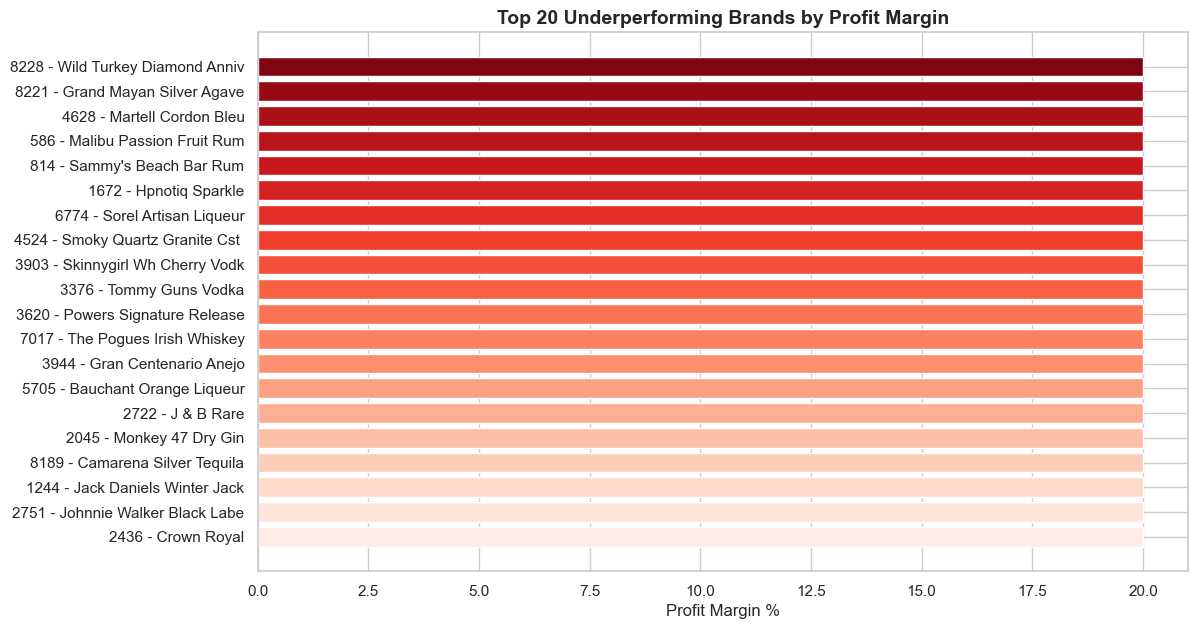

In [22]:
# Chart - Bottom 20 brands by profit margin
fig, ax = plt.subplots(figsize=(12, 7))
chart_data = df_q1.head(20).copy()
chart_data["Label"] = chart_data["Brand"].astype(str) + " - " + chart_data["Description"].str[:25]
colors = sns.color_palette("Reds_r", len(chart_data))
ax.barh(chart_data["Label"], chart_data["ProfitMarginPct"], color=colors)
ax.set_xlabel("Profit Margin %")
ax.set_title("Top 20 Underperforming Brands by Profit Margin", fontsize=14, fontweight="bold")
ax.invert_yaxis()
fig.savefig(os.path.join(OUT_DIR, "q1_underperforming_brands.png"), dpi=150, bbox_inches="tight")
plt.show()

In [7]:
q2 = """
SELECT
    s.VendorNo                                         AS VendorNumber,
    s.VendorName,
    SUM(s.SalesQuantity)                               AS TotalVolume,
    ROUND(SUM(s.SalesDollars), 2)                      AS TotalSalesDollars,
    ROUND(SUM(s.SalesDollars - s.SalesQuantity * COALESCE(pp.PurchasePrice, 0)), 2)
                                                       AS GrossProfit,
    CASE WHEN SUM(s.SalesDollars) > 0
         THEN ROUND(SUM(s.SalesDollars - s.SalesQuantity * COALESCE(pp.PurchasePrice, 0))
                    / SUM(s.SalesDollars) * 100, 2)
         ELSE 0 END                                    AS ProfitMarginPct
FROM sales s
LEFT JOIN purchase_prices pp
    ON s.Brand = pp.Brand AND s.Description = pp.Description
GROUP BY s.VendorNo, s.VendorName
ORDER BY TotalSalesDollars DESC
LIMIT 15;
"""

df_q2 = pd.read_sql_query(q2, conn)
df_q2.to_csv(os.path.join(OUT_DIR, "q2_top_vendors.csv"), index=False)
print("Q2 Results: Top 15 Vendors by Sales\n")
display(df_q2)

Q2 Results: Top 15 Vendors by Sales



,VendorNumber,VendorName,TotalVolume,TotalSalesDollars,GrossProfit,ProfitMarginPct
0,3960,DIAGEO NORTH AMERICA INC,42533,457136.47,129292.02,28.28
1,12546,JIM BEAM BRANDS COMPANY,21707,255476.93,68418.33,26.78
2,4425,MARTIGNETTI COMPANIES,14831,239705.19,89281.49,37.25
3,17035,PERNOD RICARD USA,10358,208600.72,60744.23,29.12
4,480,BACARDI USA INC,10586,168324.74,52853.28,31.40
5,1392,CONSTELLATION BRANDS INC,15536,168079.07,66637.67,39.65
6,3252,E & J GALLO WINERY,13863,145198.75,52779.29,36.35
7,1128,BROWN-FORMAN CORP,7218,132856.32,39475.79,29.71
8,9552,M S WALKER INC,11149,122712.93,40558.75,33.05
9,9165,ULTRA BEVERAGE COMPANY LLP,7628,121246.32,40555.51,33.45


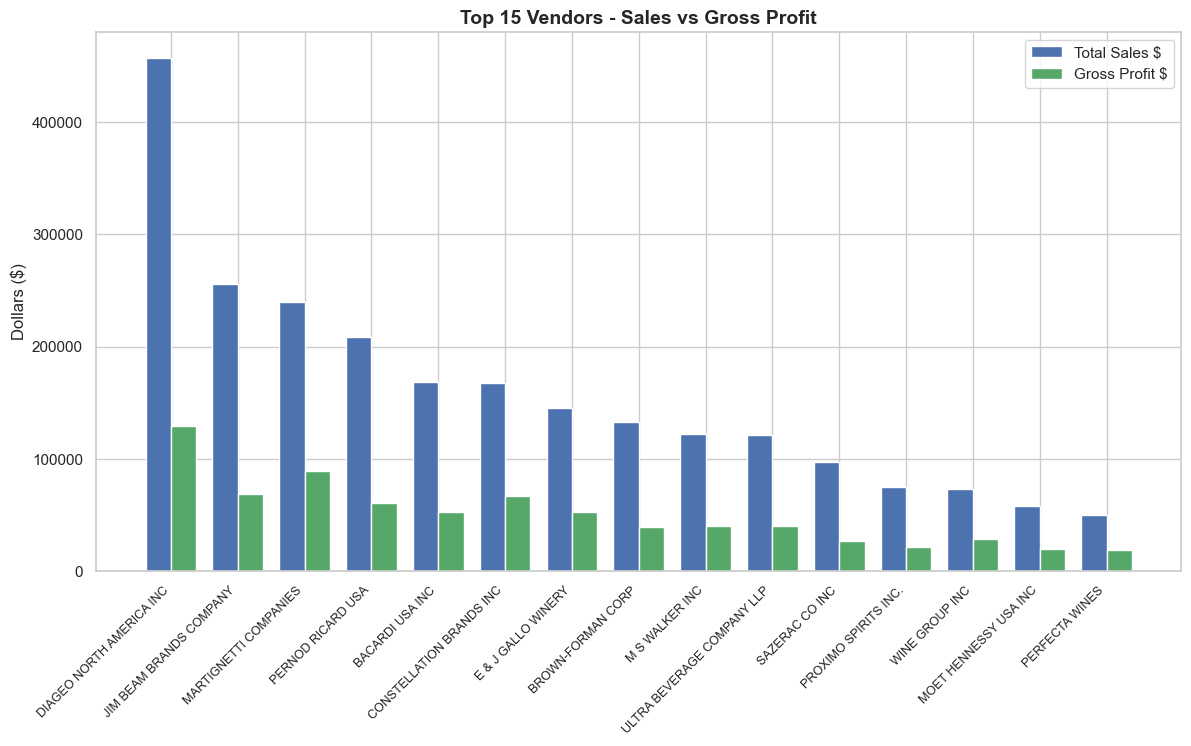

In [8]:
# Q2 Chart - Grouped bars for sales & profit
fig, ax = plt.subplots(figsize=(14, 7))
chart_data = df_q2.head(15).copy()
chart_data["Label"] = chart_data["VendorName"].str.strip().str[:30]
x = range(len(chart_data))
w = 0.38
ax.bar([i - w/2 for i in x], chart_data["TotalSalesDollars"], w, label="Total Sales $", color="#4C72B0")
ax.bar([i + w/2 for i in x], chart_data["GrossProfit"], w, label="Gross Profit $", color="#55A868")
ax.set_xticks(list(x))
ax.set_xticklabels(chart_data["Label"], rotation=45, ha="right", fontsize=9)
ax.set_ylabel("Dollars ($)")
ax.set_title("Top 15 Vendors - Sales vs Gross Profit", fontsize=14, fontweight="bold")
ax.legend()
fig.savefig(os.path.join(OUT_DIR, "q2_top_vendors.png"), dpi=150, bbox_inches="tight")
plt.show()

In [9]:
q3 = """
SELECT
    CASE
        WHEN Quantity <= 5   THEN '1-Small (1-5)'
        WHEN Quantity <= 20  THEN '2-Medium (6-20)'
        WHEN Quantity <= 100 THEN '3-Large (21-100)'
        ELSE                      '4-Bulk (100+)'
    END                                              AS PurchaseTier,
    COUNT(*)                                         AS NumTransactions,
    SUM(Quantity)                                     AS TotalUnits,
    ROUND(SUM(Dollars), 2)                           AS TotalDollars,
    ROUND(SUM(Dollars) / NULLIF(SUM(Quantity), 0), 2) AS AvgUnitCost
FROM purchases
GROUP BY PurchaseTier
ORDER BY PurchaseTier;
"""

df_q3 = pd.read_sql_query(q3, conn)
df_q3.to_csv(os.path.join(OUT_DIR, "q3_bulk_purchasing.csv"), index=False)
print("Q3 Results: Bulk Purchasing Tiers\n")
display(df_q3)

Q3 Results: Bulk Purchasing Tiers



,PurchaseTier,NumTransactions,TotalUnits,TotalDollars,AvgUnitCost
0,1-Small (1-5),19769,72807,1048964.18,14.41
1,2-Medium (6-20),67821,668177,7470020.64,11.18
2,3-Large (21-100),10193,387243,3809718.53,9.84
3,4-Bulk (100+),2217,296220,1430888.17,4.83


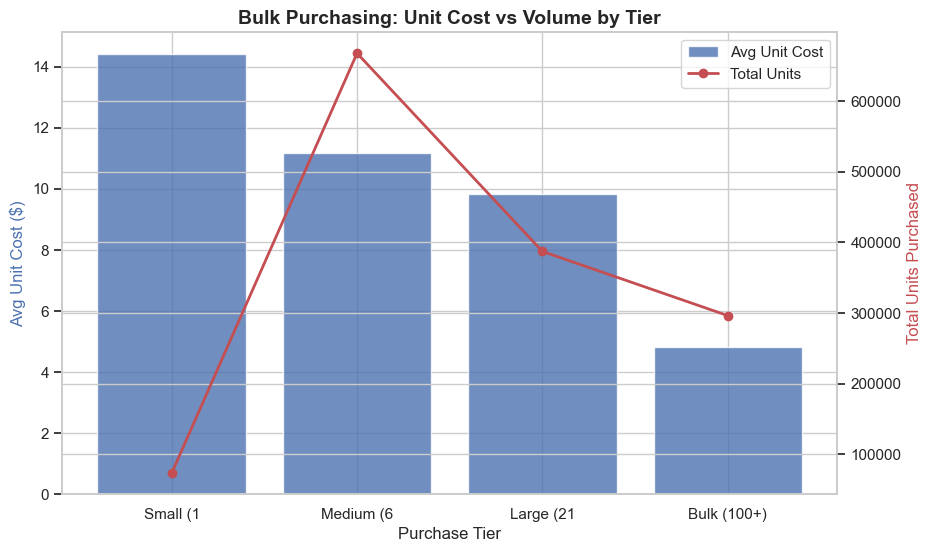

In [10]:
# Q3 Chart - Combo chart: unit cost bars + volume line
fig, ax1 = plt.subplots(figsize=(10, 6))
tier_labels = df_q3["PurchaseTier"].str.split("-").str[1]
ax1.bar(tier_labels, df_q3["AvgUnitCost"], color="#4C72B0", alpha=0.8, label="Avg Unit Cost")
ax1.set_ylabel("Avg Unit Cost ($)", color="#4C72B0")
ax1.set_xlabel("Purchase Tier")
ax2 = ax1.twinx()
ax2.plot(tier_labels, df_q3["TotalUnits"], color="#C44E52", marker="o", linewidth=2, label="Total Units")
ax2.set_ylabel("Total Units Purchased", color="#C44E52")
ax1.set_title("Bulk Purchasing: Unit Cost vs Volume by Tier", fontsize=14, fontweight="bold")
lines1, labels1 = ax1.get_legend_handles_labels()
lines2, labels2 = ax2.get_legend_handles_labels()
ax1.legend(lines1 + lines2, labels1 + labels2, loc="upper right")
fig.savefig(os.path.join(OUT_DIR, "q3_bulk_purchasing.png"), dpi=150, bbox_inches="tight")
plt.show()

In [11]:
q4 = """
WITH cogs AS (
    SELECT
        s.Brand,
        s.Description,
        SUM(s.SalesQuantity * COALESCE(pp.PurchasePrice, 0)) AS COGS
    FROM sales s
    LEFT JOIN purchase_prices pp
        ON s.Brand = pp.Brand AND s.Description = pp.Description
    GROUP BY s.Brand, s.Description
),
avg_inv AS (
    SELECT
        Brand, Description,
        AVG(InventoryValue) AS AvgInventoryValue
    FROM (
        SELECT Brand, Description, SUM(onHand * Price) AS InventoryValue
        FROM begin_inventory
        GROUP BY Brand, Description
        UNION ALL
        SELECT Brand, Description, SUM(onHand * Price) AS InventoryValue
        FROM end_inventory
        GROUP BY Brand, Description
    )
    GROUP BY Brand, Description
)
SELECT
    c.Brand,
    c.Description,
    ROUND(c.COGS, 2)                                            AS COGS,
    ROUND(ai.AvgInventoryValue, 2)                               AS AvgInventoryValue,
    ROUND(c.COGS / NULLIF(ai.AvgInventoryValue, 0), 2)          AS InventoryTurnover
FROM cogs c
JOIN avg_inv ai ON c.Brand = ai.Brand AND c.Description = ai.Description
WHERE ai.AvgInventoryValue > 0
ORDER BY InventoryTurnover DESC
LIMIT 30;
"""

df_q4 = pd.read_sql_query(q4, conn)
df_q4.to_csv(os.path.join(OUT_DIR, "q4_inventory_turnover.csv"), index=False)
print("Q4 Results: Top 30 Brands by Inventory Turnover\n")
display(df_q4)

Q4 Results: Top 30 Brands by Inventory Turnover



,Brand,Description,COGS,AvgInventoryValue,InventoryTurnover
0,24001,Lee Family Farm Rio Tinto S,128.04,16.99,7.54
1,18783,Herencia Altes Garnacha Negr,70.32,16.98,4.14
2,818,Gordons London Dry Gin,882.00,284.72,3.10
3,190,Christian Bros Ruby Port,220.32,83.66,2.63
4,44221,Vinedo de Los Vientos Estiv,130.56,63.96,2.04
5,24664,M Chiarlo 10 Chiarlo Rosso,158.88,79.92,1.99
6,39997,Tisdale Merlot Cal,93.96,47.88,1.96
7,976,McCormick Gold Label Bourbon,560.25,308.43,1.82
8,21374,10 Span Chard CC,246.24,179.76,1.37
9,22768,Stags Leap Hand of Time Red,191.88,143.94,1.33


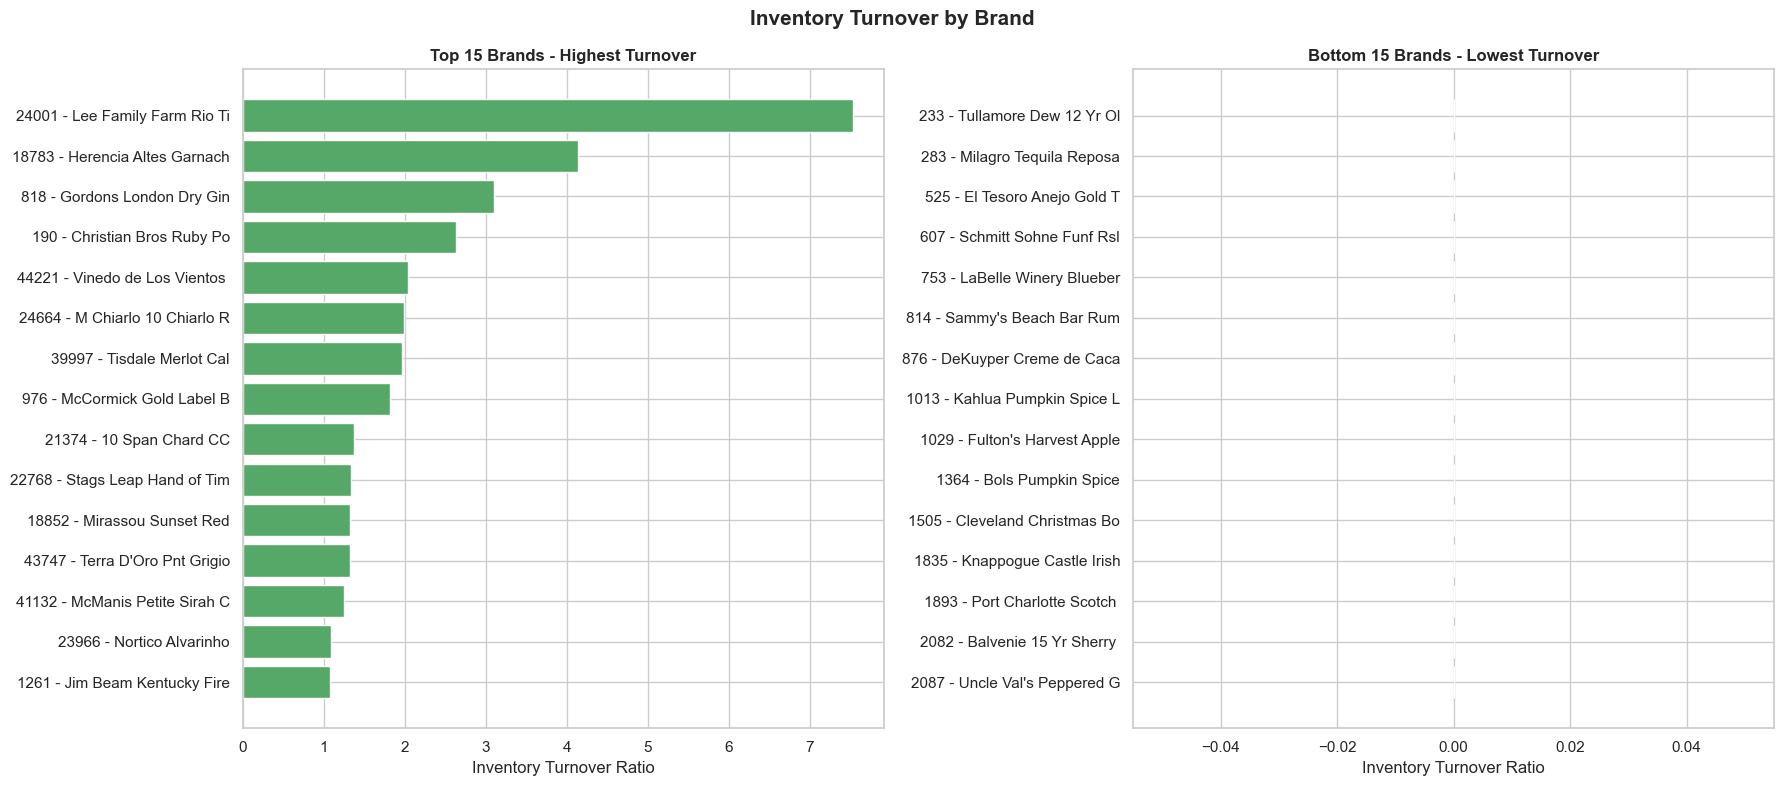

In [12]:
# Q4 Chart - Top 15 vs Bottom 15 turnover
top15 = df_q4.head(15).copy()
top15["Label"] = top15["Brand"].astype(str) + " - " + top15["Description"].str[:22]

# Get bottom 15 (re-query sorted ascending)
q4_bottom = q4.replace("ORDER BY InventoryTurnover DESC", "ORDER BY InventoryTurnover ASC")
df_q4_bot = pd.read_sql_query(q4_bottom, conn)
bot15 = df_q4_bot.head(15).copy()
bot15["Label"] = bot15["Brand"].astype(str) + " - " + bot15["Description"].str[:22]

fig, axes = plt.subplots(1, 2, figsize=(18, 8))
axes[0].barh(top15["Label"], top15["InventoryTurnover"], color="#55A868")
axes[0].set_xlabel("Inventory Turnover Ratio")
axes[0].set_title("Top 15 Brands - Highest Turnover", fontweight="bold")
axes[0].invert_yaxis()

axes[1].barh(bot15["Label"], bot15["InventoryTurnover"], color="#C44E52")
axes[1].set_xlabel("Inventory Turnover Ratio")
axes[1].set_title("Bottom 15 Brands - Lowest Turnover", fontweight="bold")
axes[1].invert_yaxis()

fig.suptitle("Inventory Turnover by Brand", fontsize=15, fontweight="bold")
plt.tight_layout()
fig.savefig(os.path.join(OUT_DIR, "q4_inventory_turnover.png"), dpi=150, bbox_inches="tight")
plt.show()

In [13]:
q5 = """
WITH vendor_profit AS (
    SELECT
        s.VendorNo                                     AS VendorNumber,
        s.VendorName,
        SUM(s.SalesQuantity)                           AS TotalQty,
        ROUND(SUM(s.SalesDollars), 2)                  AS TotalSales,
        ROUND(SUM(s.SalesDollars - s.SalesQuantity
              * COALESCE(pp.PurchasePrice, 0)), 2)     AS GrossProfit,
        CASE WHEN SUM(s.SalesDollars) > 0
             THEN ROUND(SUM(s.SalesDollars - s.SalesQuantity
                        * COALESCE(pp.PurchasePrice, 0))
                        / SUM(s.SalesDollars) * 100, 2)
             ELSE 0 END                                AS ProfitMarginPct
    FROM sales s
    LEFT JOIN purchase_prices pp
        ON s.Brand = pp.Brand AND s.Description = pp.Description
    GROUP BY s.VendorNo, s.VendorName
    HAVING SUM(s.SalesQuantity) >= 10
),
ranked AS (
    SELECT *, 'Top 10' AS Tier
    FROM vendor_profit
    ORDER BY ProfitMarginPct DESC
    LIMIT 10
),
ranked_bottom AS (
    SELECT *, 'Bottom 10' AS Tier
    FROM vendor_profit
    ORDER BY ProfitMarginPct ASC
    LIMIT 10
)
SELECT * FROM ranked
UNION ALL
SELECT * FROM ranked_bottom
ORDER BY ProfitMarginPct DESC;
"""

df_q5 = pd.read_sql_query(q5, conn)
df_q5.to_csv(os.path.join(OUT_DIR, "q5_vendor_profitability_variance.csv"), index=False)
print("Q5 Results: Top 10 vs Bottom 10 Vendors\n")
display(df_q5)

Q5 Results: Top 10 vs Bottom 10 Vendors



,VendorNumber,VendorName,TotalQty,TotalSales,GrossProfit,ProfitMarginPct,Tier
0,17033,SEA BREEZE CELLARS LLC,66,1123.34,560.87,49.93,Top 10
1,10000,MAJESTIC FINE WINES,1340,18468.24,8500.51,46.03,Top 10
2,8673,STE MICHELLE WINE ESTATES,2337,29957.97,12867.66,42.95,Top 10
3,9819,TREASURY WINE ESTATES,2395,24998.73,10715.12,42.86,Top 10
4,1590,DIAGEO CHATEAU ESTATE WINES,1676,19675.12,8360.40,42.49,Top 10
5,2242,DELICATO VINEYARDS INC,1151,16265.09,6791.19,41.75,Top 10
6,1587,VINEYARD BRANDS INC,1022,11182.78,4619.34,41.31,Top 10
7,2000,SOUTHERN WINE & SPIRITS NE,2144,31582.56,12995.99,41.15,Top 10
8,9260,TY KU LLC,10,145.90,59.90,41.06,Top 10
9,4950,LATITUDE BEVERAGE COMPANY,265,2506.35,1005.77,40.13,Top 10


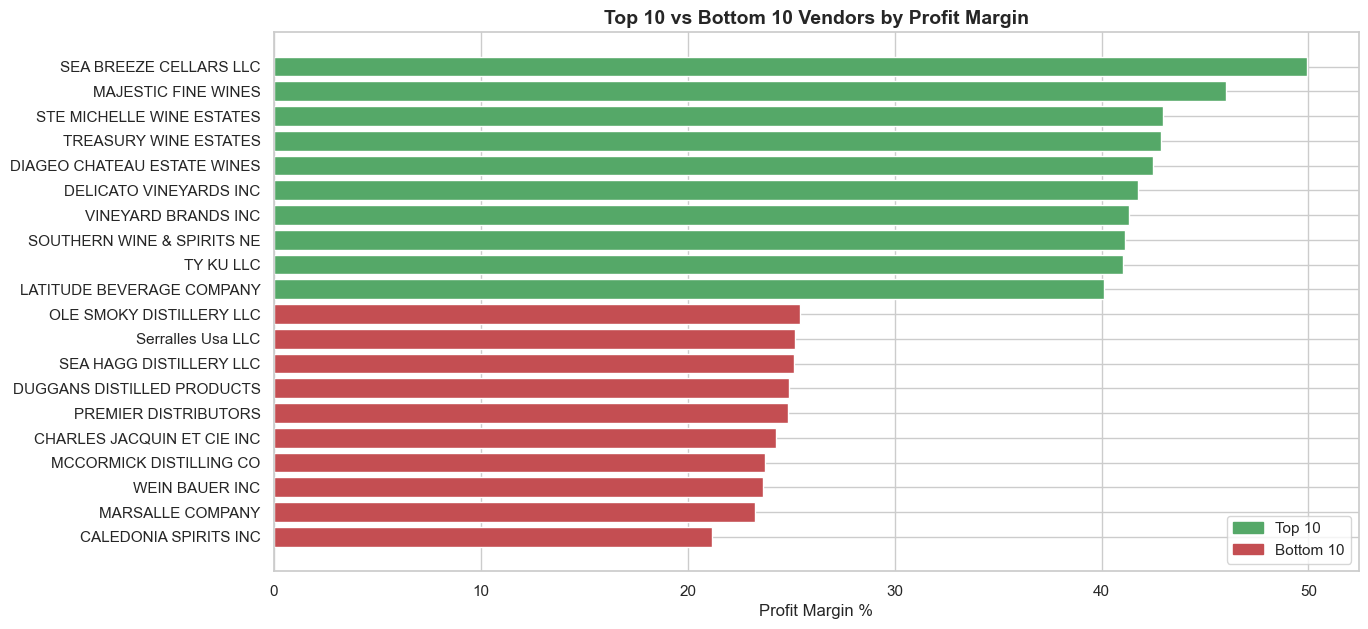

In [14]:
# Q5 Chart - Top 10 vs Bottom 10 comparison
fig, ax = plt.subplots(figsize=(14, 7))
top10 = df_q5[df_q5["Tier"] == "Top 10"].copy()
bot10 = df_q5[df_q5["Tier"] == "Bottom 10"].copy()

combined = pd.concat([top10, bot10])
combined["Label"] = combined["VendorName"].str.strip().str[:28]
colors = ["#55A868" if t == "Top 10" else "#C44E52" for t in combined["Tier"]]
ax.barh(combined["Label"], combined["ProfitMarginPct"], color=colors)
ax.set_xlabel("Profit Margin %")
ax.set_title("Top 10 vs Bottom 10 Vendors by Profit Margin", fontsize=14, fontweight="bold")
ax.invert_yaxis()
ax.legend(handles=[Patch(color="#55A868", label="Top 10"),
                   Patch(color="#C44E52", label="Bottom 10")])
fig.savefig(os.path.join(OUT_DIR, "q5_vendor_profitability.png"), dpi=150, bbox_inches="tight")
plt.show()

In [15]:
conn.close()
print("✔ Database connection closed.")
print(f"\n✔ All output files saved to: {OUT_DIR}")
print("\nGenerated files:")
for f in sorted(os.listdir(OUT_DIR)):
    if f.endswith(('.png', '.csv')):
        print(f"  - {f}")

✔ Database connection closed.

✔ All output files saved to: c:\Users\Asus\Desktop\Vendor Performance Data Analytics\outputs

Generated files:
  - inventory_delta.csv
  - plot_01_top20_purchase_spend.png
  - plot_02_avg_lead_time.png
  - plot_03_gross_margin_dist.png
  - plot_04_lead_time_dist.png
  - plot_05_lead_vs_margin.png
  - plot_06_profit_contribution.png
  - purchases_enriched.csv
  - q1_underperforming_brands.csv
  - q1_underperforming_brands.png
  - q2_top_vendors.csv
  - q2_top_vendors.png
  - q3_bulk_purchasing.csv
  - q3_bulk_purchasing.png
  - q4_inventory_turnover.csv
  - q4_inventory_turnover.png
  - q5_vendor_profitability.png
  - q5_vendor_profitability_variance.csv
  - vendor_summary.csv
